<a href="https://colab.research.google.com/github/martinrims360/ERP_KCF/blob/main/python_analisis_dengue_peru_mejorado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de brotes de dengue en Perú (4 semanas de anticipación)

Versión mejorada. Cambios principales respecto a la anterior:

1. Una sola lectura del CSV y un EDA coherente con el panel que usa el modelo.
2. Los **tres modelos** se comparan en igualdad de condiciones (Gradient Boosting ahora también usa pesos balanceados).
3. El mejor modelo se elige con **validación cruzada temporal** según el criterio que definas (`CRITERIO_SELECCION`: exactitud, precisión, sensibilidad o F1), nunca con la prueba.
4. Se generan **todos los gráficos comparativos** (se muestran en pantalla y se guardan a 300 dpi en `salidas_dengue/`).

**Datos:** Vigilancia Epidemiológica de dengue (CDC Perú - MINSA), Plataforma Nacional de Datos Abiertos (licencia ODC-BY).
Si el CSV no está en `/content`, la celda de lectura te pedirá subirlo.

In [13]:
import os, csv, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------- Parámetros
SEED = 42
START_YEAR = 2005          # año inicial (antes hay notificación muy escasa)
TRAIN_END = 2014           # entrenamiento: hasta este año (ajustado para datos hasta 2015)
TEST_START = 2015          # prueba: desde este año (ajustado para datos hasta 2015)
VAL_YEARS = [2011, 2012, 2013, 2014]   # validación cruzada temporal adaptada a la escala temporal real
HORIZON = 4                # semanas de anticipación
MIN_CASOS_SEMANA = 10      # mínimo de casos semanales para considerar brote
MIN_CASOS_DEPTO = 1000     # se excluyen departamentos con menos casos acumulados
TRIM_LAST_WEEKS = 3        # se descartan las últimas semanas (retraso de notificación)

# Elección del mejor modelo (se decide SOLO con la validación cruzada):
CRITERIO_SELECCION = "F1"  # "exactitud", "precision", "sensibilidad" o "F1"
# Si es True, el umbral de decisión de cada modelo se optimiza (F1) con las predicciones
# fuera de muestra de la validación cruzada y luego se aplica a la prueba. Si es False, se usa 0.5.
OPTIMIZAR_UMBRAL = False

RUTA_CSV = None            # opcional: escribe aquí la ruta de tu CSV
OUT = "salidas_dengue"
os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)

COL = {"Regresión logística": "#1f4e79", "Random Forest": "#2e86c1", "Gradient Boosting": "#f39c12",
       "Persistencia (brote actual)": "#7f8c8d", "Clase mayoritaria": "#bdc3c7"}
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})


def guardar(fig, nombre):
    """Guarda la figura a 300 dpi y la muestra en pantalla."""
    fig.tight_layout()
    fig.savefig(f"{OUT}/{nombre}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Lectura y limpieza

In [15]:
NEEDED = {"departamento", "enfermedad", "ano", "semana", "tipo_dx"}


def encontrar_csv():
    if RUTA_CSV:
        return RUTA_CSV
    candidatos = []
    for carpeta in [".", "/content", "/content/salidas_dengue", OUT]:
        candidatos += glob.glob(os.path.join(carpeta, "*dengue*.csv"))
    candidatos = [c for c in candidatos if "panel_dengue" not in c]
    if candidatos:
        return candidatos[0]
    try:                                   # Colab: pedir el archivo
        from google.colab import files
        subido = files.upload()
        return list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError("No encontré el CSV. Define RUTA_CSV en la celda de parámetros.")


def leer(path):
    last_err = None
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            with open(path, encoding=enc, errors="strict") as f:
                first = f.readline()
            try:
                sep = csv.Sniffer().sniff(first, delimiters=",;|\t").delimiter
            except csv.Error:
                sep = ","
            return pd.read_csv(path, sep=sep, encoding=enc, dtype=str,
                               usecols=lambda c: c.strip().lower() in NEEDED)
        except UnicodeDecodeError as e:
            last_err = e
    raise last_err


PATH = encontrar_csv()
print(f"Leyendo {PATH} ...")
raw = leer(PATH)
raw.columns = [c.strip().lower() for c in raw.columns]
print(f"Registros leídos: {len(raw):,}")

raw["ano"] = pd.to_numeric(raw["ano"], errors="coerce")
raw["semana"] = pd.to_numeric(raw["semana"], errors="coerce")
raw = raw.dropna(subset=["ano", "semana"])
raw["ano"] = raw["ano"].astype(int)
raw["semana"] = raw["semana"].astype(int)
raw["tipo_dx"] = raw["tipo_dx"].astype(str).str.strip().str.upper()
raw["departamento"] = raw["departamento"].astype(str).str.strip().str.upper()
raw = raw[raw["enfermedad"].astype(str).str.upper().str.contains("DENGUE")]
n_all = len(raw)
raw = raw[raw["tipo_dx"].isin(["C", "P"])]            # confirmados + probables
raw = raw[(raw["ano"] >= START_YEAR) & raw["semana"].between(1, 53)]
print(f"Casos de dengue (confirmados + probables) desde {START_YEAR}: {len(raw):,} "
      f"(de {n_all:,} registros de dengue)")

Leyendo /content/salidas_dengue/datos_abiertos_vigilancia_dengue_2000_2025_0.csv ...
Registros leídos: 1,065,274
Casos de dengue (confirmados + probables) desde 2005: 1,015,209 (de 1,065,274 registros de dengue)


In [16]:
# Celda de diagnóstico temporal para inspeccionar los años presentes en el archivo físico
import pandas as pd
print("Ruta del archivo encontrado:", PATH)

# Leemos rápidamente la columna 'ano' con bajo consumo de memoria para ver los valores únicos reales
try:
    df_check = pd.read_csv(PATH, usecols=lambda c: c.strip().lower() == 'ano')
    df_check.columns = [c.strip().lower() for c in df_check.columns]
    valores_unicos = sorted(df_check['ano'].dropna().unique())
    print("Años detectados en el CSV original:", valores_unicos)
except Exception as e:
    print("Error al inspeccionar la columna 'ano':", e)


Ruta del archivo encontrado: /content/salidas_dengue/datos_abiertos_vigilancia_dengue_2000_2025_0.csv
Años detectados en el CSV original: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [17]:
# Celda de diagnóstico para analizar filtros de enfermedad y tipo_dx en años recientes (>2015)
import pandas as pd
try:
    # Leemos una muestra rápida de las columnas relevantes
    df_diag = pd.read_csv(PATH, usecols=lambda c: c.strip().lower() in ['ano', 'enfermedad', 'tipo_dx'])
    df_diag.columns = [c.strip().lower() for c in df_diag.columns]

    print("--- Análisis para años > 2015 ---")
    recientes = df_diag[df_diag['ano'].astype(float) > 2015]
    print(f"Total de filas encontradas para > 2015: {len(recientes):,}")

    if len(recientes) > 0:
        print("\nValores únicos de 'enfermedad':")
        print(recientes['enfermedad'].value_counts(dropna=False).head(10))

        print("\nValores únicos de 'tipo_dx':")
        print(recientes['tipo_dx'].value_counts(dropna=False).head(10))
except Exception as e:
    print("Error en diagnóstico:", e)

--- Análisis para años > 2015 ---
Total de filas encontradas para > 2015: 833,400

Valores únicos de 'enfermedad':
enfermedad
DENGUE SIN SIGNOS DE ALARMA    736405
DENGUE CON SIGNOS DE ALARMA     93912
DENGUE GRAVE                     3083
Name: count, dtype: int64

Valores únicos de 'tipo_dx':
tipo_dx
C    785738
P     47662
Name: count, dtype: int64


In [18]:
# Celda de diagnóstico para analizar filtros de enfermedad y tipo_dx en años recientes (>2015)
import pandas as pd
try:
    # Leemos una muestra rápida de las columnas relevantes
    df_diag = pd.read_csv(PATH, usecols=lambda c: c.strip().lower() in ['ano', 'enfermedad', 'tipo_dx'])
    df_diag.columns = [c.strip().lower() for c in df_diag.columns]

    print("--- Análisis para años > 2015 ---")
    recientes = df_diag[df_diag['ano'].astype(float) > 2015]
    print(f"Total de filas encontradas para > 2015: {len(recientes):,}")

    if len(recientes) > 0:
        print("\nValores únicos de 'enfermedad':")
        print(recientes['enfermedad'].value_counts(dropna=False).head(10))

        print("\nValores únicos de 'tipo_dx':")
        print(recientes['tipo_dx'].value_counts(dropna=False).head(10))
except Exception as e:
    print("Error en diagnóstico:", e)

--- Análisis para años > 2015 ---
Total de filas encontradas para > 2015: 833,400

Valores únicos de 'enfermedad':
enfermedad
DENGUE SIN SIGNOS DE ALARMA    736405
DENGUE CON SIGNOS DE ALARMA     93912
DENGUE GRAVE                     3083
Name: count, dtype: int64

Valores únicos de 'tipo_dx':
tipo_dx
C    785738
P     47662
Name: count, dtype: int64


## 2. Exploración de datos (usa los mismos datos filtrados que el modelo)

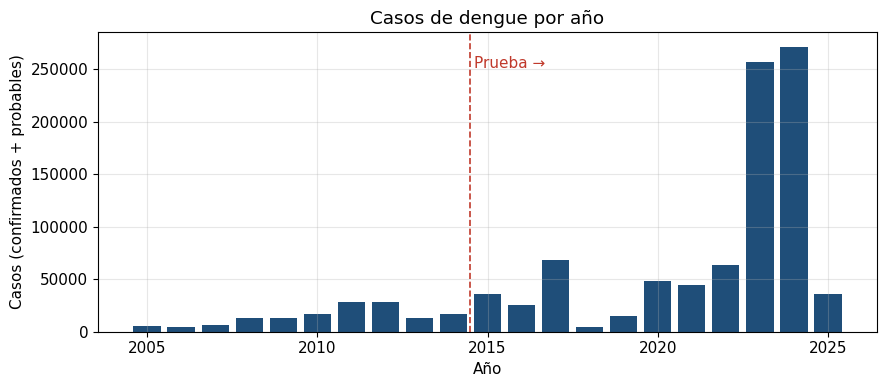

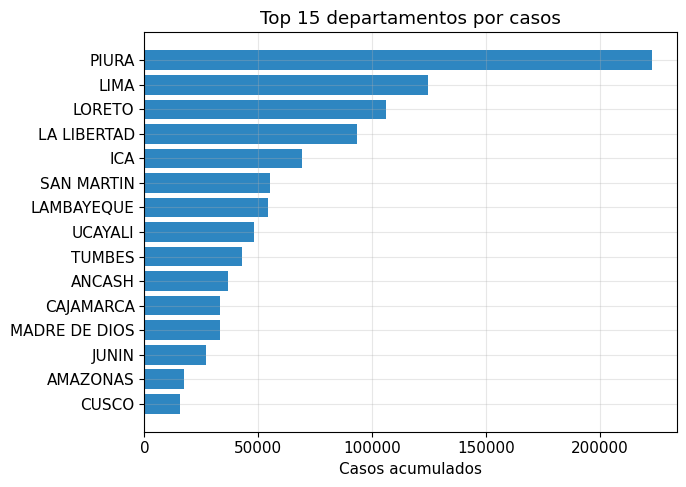

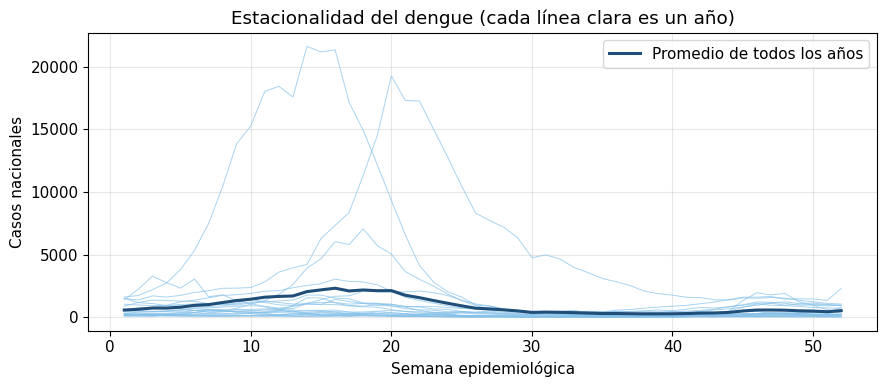

In [19]:
# Fig. EDA 1: casos por año
por_anio = raw.groupby("ano").size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_anio.index, por_anio.values, color="#1f4e79")
ax.axvline(TEST_START - 0.5, color="#c0392b", ls="--", lw=1.2)
ax.text(TEST_START - 0.4, ax.get_ylim()[1] * 0.92, "Prueba →", color="#c0392b", va="top")
ax.set_xlabel("Año"); ax.set_ylabel("Casos (confirmados + probables)")
ax.set_title("Casos de dengue por año")
guardar(fig, "eda1_casos_por_anio")

# Fig. EDA 2: departamentos con más casos
top = raw.groupby("departamento").size().sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color="#2e86c1")
ax.set_xlabel("Casos acumulados"); ax.set_title("Top 15 departamentos por casos")
guardar(fig, "eda2_top_departamentos")

# Fig. EDA 3: estacionalidad (casos medios por semana epidemiológica)
sem = raw.assign(sem52=raw["semana"].clip(upper=52)).groupby(["ano", "sem52"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4))
for a in sem.index:
    ax.plot(sem.columns, sem.loc[a], color="#85c1e9", lw=0.7, alpha=0.7)
ax.plot(sem.columns, sem.mean(), color="#1f4e79", lw=2.2, label="Promedio de todos los años")
ax.set_xlabel("Semana epidemiológica"); ax.set_ylabel("Casos nacionales")
ax.set_title("Estacionalidad del dengue (cada línea clara es un año)")
ax.legend()
guardar(fig, "eda3_estacionalidad")

## 3. Panel semanal por departamento

Departamentos incluidos (19): AMAZONAS, ANCASH, AYACUCHO, CAJAMARCA, CALLAO, CUSCO, HUANUCO, ICA, JUNIN, LA LIBERTAD, LAMBAYEQUE, LIMA, LORETO, MADRE DE DIOS, PASCO, PIURA, SAN MARTIN, TUMBES, UCAYALI
Panel: 20,786 filas (19 departamentos x 1094 semanas)


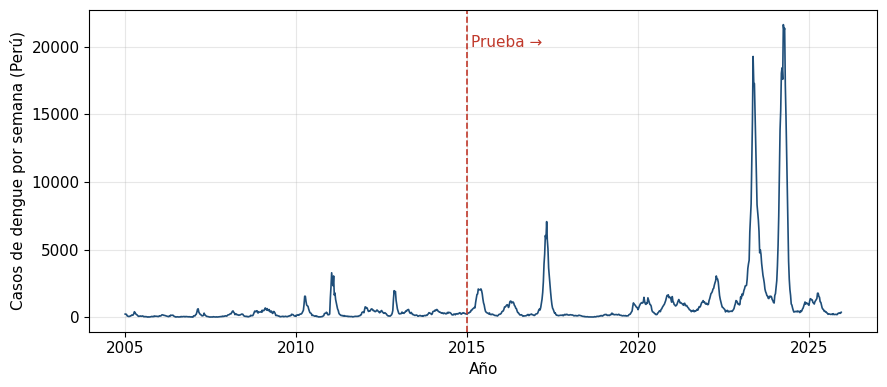

In [20]:
conteo = raw.groupby(["departamento", "ano", "semana"]).size().rename("casos")

# Semanas válidas: 1..52 siempre; la 53 solo si existe en el archivo ese año.
sem53 = set(raw.loc[raw.semana == 53, "ano"].unique())
last_year = int(raw["ano"].max())
last_week = int(raw.loc[raw.ano == last_year, "semana"].max())
weeks = []
for a in range(START_YEAR, last_year + 1):
    for s in range(1, 54):
        if s == 53 and a not in sem53:
            continue
        if a == last_year and s > last_week:
            continue
        weeks.append((a, s))
weeks = weeks[:len(weeks) - TRIM_LAST_WEEKS]
wk = pd.DataFrame(weeks, columns=["ano", "semana"]).reset_index(names="t")

tot = conteo.groupby("departamento").sum()
deptos = sorted(tot[tot >= MIN_CASOS_DEPTO].index)
print(f"Departamentos incluidos ({len(deptos)}): {', '.join(deptos)}")

panel = (pd.MultiIndex.from_product([deptos, range(len(wk))], names=["departamento", "t"])
         .to_frame(index=False).merge(wk, on="t"))
panel = panel.merge(conteo.reset_index(), on=["departamento", "ano", "semana"], how="left")
panel["casos"] = panel["casos"].fillna(0).astype(int)
panel = panel.sort_values(["departamento", "t"]).reset_index(drop=True)
panel.to_csv(f"{OUT}/panel_dengue_semanal_departamento.csv", index=False)
print(f"Panel: {len(panel):,} filas ({len(deptos)} departamentos x {len(wk)} semanas)")

# Fig. 1: serie nacional semanal
nac = panel.groupby("t")["casos"].sum()
fechas = wk.set_index("t")
x = fechas["ano"] + (fechas["semana"] - 1) / 52
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x.loc[nac.index], nac.values, color="#1f4e79", lw=1.2)
ax.axvline(TEST_START, color="#c0392b", ls="--", lw=1.2)
ax.text(TEST_START + 0.1, ax.get_ylim()[1] * 0.92, "Prueba →", color="#c0392b", va="top")
ax.set_ylabel("Casos de dengue por semana (Perú)"); ax.set_xlabel("Año")
guardar(fig, "figura1_serie_nacional")

## 4. Variables, variable objetivo y modelos

In [21]:
def canal_endemico(df, year_max):
    """Límite superior (media + 2 DE) por departamento y semana del año con años <= year_max."""
    tr = df[df["ano"] <= year_max].copy()
    tr["sem52"] = tr["semana"].clip(upper=52)
    lim = {}
    for d, g in tr.groupby("departamento"):
        mat = g.pivot_table(index="ano", columns="sem52", values="casos", aggfunc="sum").reindex(columns=range(1, 53))
        for w in range(1, 53):
            vecinas = [((w - 2 + k) % 52) + 1 for k in range(3)]       # w-1, w, w+1 (circular)
            vals = mat[vecinas].to_numpy().ravel()
            vals = vals[~np.isnan(vals)]
            lim[(d, w)] = (vals.mean() + 2 * vals.std(ddof=0)) if len(vals) else 0.0
    return lim


def construir(df, canal_hasta):
    """Devuelve X, y y metadatos; el umbral de brote se calcula solo con años <= canal_hasta."""
    d = df.copy()
    lim = canal_endemico(d, canal_hasta)
    d["sem52"] = d["semana"].clip(upper=52)
    d["umbral"] = [max(lim[(a, b)], MIN_CASOS_SEMANA) for a, b in zip(d["departamento"], d["sem52"])]
    d["log_c0"] = np.log1p(d["casos"])
    g = d.groupby("departamento", sort=False)           # se crea después de añadir log_c0
    for k in (1, 2, 3, 4):
        d[f"log_c{k}"] = g["log_c0"].shift(k)
    d["media4"] = g["log_c0"].transform(lambda s: s.rolling(4).mean())
    d["acum12"] = np.log1p(g["casos"].transform(lambda s: s.rolling(12).sum()))
    d["cambio4"] = d["log_c0"] - d["log_c4"]
    d["sobre_umbral_ahora"] = (d["casos"] > d["umbral"]).astype(int)
    d["log_ratio_umbral"] = np.log1p(d["casos"]) - np.log1p(d["umbral"])
    d["sen_sem"] = np.sin(2 * np.pi * d["sem52"] / 52)
    d["cos_sem"] = np.cos(2 * np.pi * d["sem52"] / 52)
    fut_casos = g["casos"].shift(-HORIZON)
    fut_umbral = g["umbral"].shift(-HORIZON)
    d["y"] = (fut_casos > fut_umbral).astype(float).where(fut_casos.notna())
    d["ano_objetivo"] = g["ano"].shift(-HORIZON)
    dummies = pd.get_dummies(d["departamento"], prefix="dep", dtype=int)
    d = pd.concat([d, dummies], axis=1)
    d = d.dropna(subset=["log_c4", "acum12", "y", "ano_objetivo"]).copy()
    d["y"] = d["y"].astype(int)
    return d


NUM_A = ["log_c0", "log_c1", "log_c2", "log_c3", "media4", "acum12", "cambio4",
         "sobre_umbral_ahora", "log_ratio_umbral", "sen_sem", "cos_sem"]
CONJ_A, CONJ_B, BASE = "A. Completo", "B. Solo estacionalidad y lugar", "Línea base"
PERS = "Persistencia (brote actual)"

# Los tres modelos, todos con balanceo de clases (GB lo recibe vía sample_weight en ajustar()).
MODELS = {
    "Regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight="balanced",
        n_jobs=-1, random_state=SEED),
    "Gradient Boosting": lambda: GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED),
}


def ajustar(nombre, modelo, X, y):
    if nombre == "Gradient Boosting":
        modelo.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        modelo.fit(X, y)
    return modelo


METS = ["exactitud", "precision", "sensibilidad", "F1"]


def metricas(y_true, y_pred, y_prob=None):
    m = {"exactitud": accuracy_score(y_true, y_pred),
         "exactitud_bal": balanced_accuracy_score(y_true, y_pred),
         "precision": precision_score(y_true, y_pred, zero_division=0),
         "sensibilidad": recall_score(y_true, y_pred, zero_division=0),
         "F1": f1_score(y_true, y_pred, zero_division=0)}
    if y_prob is not None and len(set(y_true)) > 1:
        m["AUC"] = roc_auc_score(y_true, y_prob)
        m["AUC_PR"] = average_precision_score(y_true, y_prob)
    else:
        m["AUC"], m["AUC_PR"] = np.nan, np.nan
    return m


def mejor_umbral(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, (p >= u).astype(int), zero_division=0) for u in grid]
    return float(grid[int(np.argmax(f1s))])

## 5. Validación cruzada temporal (aquí se elige el mejor modelo)

Cada fold entrena con años anteriores al año validado, y el umbral de brote se calcula solo con esos años.

In [22]:
cv_rows = []
oof = {}                                     # predicciones fuera de muestra, por (conjunto, modelo)
for vy in VAL_YEARS:
    D = construir(panel, vy - 1)             # umbral con años anteriores al año validado
    dep_cols = [c for c in D.columns if c.startswith("dep_")]
    conjuntos = {CONJ_A: NUM_A + dep_cols, CONJ_B: ["sen_sem", "cos_sem"] + dep_cols}
    tr = D[D["ano_objetivo"] < vy]
    va = D[D["ano"] == vy]
    for sname, feats in conjuntos.items():
        for mname, mk in MODELS.items():
            mdl = ajustar(mname, mk(), tr[feats], tr["y"])
            prob = mdl.predict_proba(va[feats])[:, 1]
            cv_rows.append({"anio_validacion": vy, "conjunto": sname, "modelo": mname,
                            **metricas(va["y"], (prob >= 0.5).astype(int), prob)})
            oof.setdefault((sname, mname), []).append((va["y"].to_numpy(), prob))
    cv_rows.append({"anio_validacion": vy, "conjunto": BASE, "modelo": PERS,
                    **metricas(va["y"], va["sobre_umbral_ahora"])})
cv = pd.DataFrame(cv_rows)

cols = METS + ["exactitud_bal", "AUC", "AUC_PR"]
cv_sum = cv.groupby(["conjunto", "modelo"])[cols].agg(["mean", "std"])
cv_sum.columns = [f"{a}_{b}" for a, b in cv_sum.columns]
cv_sum.round(3).to_csv(f"{OUT}/validacion_cruzada_resumen.csv")
cv.round(3).to_csv(f"{OUT}/validacion_cruzada_por_fold.csv", index=False)
print("Validación cruzada temporal (media ± DE de %d años)" % len(VAL_YEARS))
display(cv_sum[[f"{m}_{s}" for m in METS for s in ("mean", "std")]].round(3))

# ---- Elección del mejor modelo según el criterio elegido (solo conjunto A, solo validación cruzada)
cv_A = cv[cv.conjunto == CONJ_A].groupby("modelo")[METS].mean()
ranking_cv = cv_A.sort_values(CRITERIO_SELECCION, ascending=False)
best = ranking_cv.index[0]
print(f"\nRanking en validación cruzada según {CRITERIO_SELECCION}:")
display(ranking_cv.round(3))
print(f"Mejor modelo: {best}")

# ---- Umbrales de decisión (0.5 o los optimizados con predicciones fuera de muestra)
UMBRALES = {k: 0.5 for k in oof}
if OPTIMIZAR_UMBRAL:
    for k, lst in oof.items():
        UMBRALES[k] = mejor_umbral(np.concatenate([a for a, _ in lst]), np.concatenate([b for _, b in lst]))
    print("Umbrales optimizados:", {f"{k[1]} ({k[0][0]})": round(v, 2) for k, v in UMBRALES.items()})

Validación cruzada temporal (media ± DE de 4 años)


exactitud_mean  \
conjunto                       modelo                                        
A. Completo                    Gradient Boosting                     0.816   
                               Random Forest                         0.850   
                               Regresión logística                   0.782   
B. Solo estacionalidad y lugar Gradient Boosting                     0.581   
                               Random Forest                         0.645   
                               Regresión logística                   0.590   
Línea base                     Persistencia (brote actual)           0.904   

                                                            exactitud_std  \
conjunto                       modelo                                       
A. Completo                    Gradient Boosting                    0.037   
                               Random Forest                        0.023   
                               Regresión logística                  0.051   
B. Solo estacionalidad y lugar Gradient Boosting                    0.072   
                               Random Forest                        0.061   
                               Regresión logística                  0.025   
Línea base                     Persistencia (brote actual)          0.031   

                                                            precision_mean  \
conjunto                       modelo                                        
A. Completo                    Gradient Boosting                     0.326   
                               Random Forest                         0.394   
                               Regresión logística                   0.319   
B. Solo estacionalidad y lugar Gradient Boosting                     0.168   
                               Random Forest                         0.166   
                               Regresión logística                   0.178   
Línea base                     Persistencia (brote actual)           0.542   

                                                            precision_std  \
conjunto                       modelo                                       
A. Completo                    Gradient Boosting                    0.083   
                               Random Forest                        0.093   
                               Regresión logística                  0.057   
B. Solo estacionalidad y lugar Gradient Boosting                    0.081   
                               Random Forest                        0.073   
                               Regresión logística                  0.066   
Línea base                     Persistencia (brote actual)          0.125   

                                                            sensibilidad_mean  \
conjunto                       modelo                                           
A. Completo                    Gradient Boosting                        0.695   
                               Random Forest                            0.764   
                               Regresión logística                      0.906   
B. Solo estacionalidad y lugar Gradient Boosting                        0.675   
                               Random Forest                            0.533   
                               Regresión logística                      0.755   
Línea base                     Persistencia (brote actual)              0.550   

                                                            sensibilidad_std  \
conjunto                       modelo                                          
A. Completo                    Gradient Boosting                       0.150   
                               Random Forest                           0.124   
                               Regresión logística                     0.050   
B. Solo estacionalidad y lugar Gradient Boosting                       0.081   
                               Random Forest            


Ranking en validación cruzada según F1:


,exactitud,precision,sensibilidad,F1
modelo,,,,
Random Forest,0.850,0.394,0.764,0.515
Regresión logística,0.782,0.319,0.906,0.470
Gradient Boosting,0.816,0.326,0.695,0.441


Mejor modelo: Random Forest


## 6. Prueba final (años desde `TEST_START`)

In [23]:
D = construir(panel, TRAIN_END)
dep_cols = [c for c in D.columns if c.startswith("dep_")]
CONJUNTOS = {CONJ_A: NUM_A + dep_cols, CONJ_B: ["sen_sem", "cos_sem"] + dep_cols}
tr = D[D["ano_objetivo"] <= TRAIN_END]
te = D[D["ano"] >= TEST_START]
print(f"Entrenamiento: {len(tr):,} filas | Prueba: {len(te):,} filas")
print(f"Prevalencia de brote: entrenamiento={tr['y'].mean():.3f} | prueba={te['y'].mean():.3f}")

maj = int(tr["y"].mean() >= 0.5)
pred_maj = np.full(len(te), maj)
pred_pers = te["sobre_umbral_ahora"].to_numpy()
filas = [{"conjunto": BASE, "modelo": "Clase mayoritaria", **metricas(te["y"], pred_maj)},
         {"conjunto": BASE, "modelo": PERS, **metricas(te["y"], pred_pers)}]

ajustados = {}
for sname, feats in CONJUNTOS.items():
    for mname, mk in MODELS.items():
        mdl = ajustar(mname, mk(), tr[feats], tr["y"])
        prob = mdl.predict_proba(te[feats])[:, 1]
        pred = (prob >= UMBRALES[(sname, mname)]).astype(int)
        ajustados[(sname, mname)] = (mdl, pred, prob, feats)
        filas.append({"conjunto": sname, "modelo": mname, **metricas(te["y"], pred, prob)})
res = pd.DataFrame(filas)
res.round(3).to_csv(f"{OUT}/resultados_prueba.csv", index=False)
display(res.round(3))

# Tabla lista para el artículo: validación cruzada (media ± DE) y prueba
tab = []
for (s, m), g in cv.groupby(["conjunto", "modelo"]):
    r = res[(res.conjunto == s) & (res.modelo == m)].iloc[0]
    fila = {"conjunto": s, "modelo": m}
    for met in METS:
        fila[f"CV {met}"] = f"{g[met].mean():.3f} ± {g[met].std():.3f}"
    for met in METS:
        fila[f"Prueba {met}"] = round(r[met], 3)
    tab.append(fila)
tabla_articulo = pd.DataFrame(tab)
tabla_articulo.to_csv(f"{OUT}/tabla_comparacion_modelos.csv", index=False)
display(tabla_articulo)

mdl_best, pred_best, prob_best, feats_best = ajustados[(CONJ_A, best)]
print(f"\nMejor modelo (elegido en validación cruzada por {CRITERIO_SELECCION}): {best}")
print("Matriz de confusión en prueba [[VN, FP],[FN, VP]]:\n", confusion_matrix(te["y"], pred_best))

Entrenamiento: 9,652 filas | Prueba: 10,773 filas
Prevalencia de brote: entrenamiento=0.040 | prueba=0.327


,conjunto,modelo,exactitud,exactitud_bal,precision,sensibilidad,F1,AUC,AUC_PR
0,Línea base,Clase mayoritaria,0.673,0.500,0.000,0.000,0.000,NaN,NaN
1,Línea base,Persistencia (brote actual),0.878,0.862,0.814,0.814,0.814,NaN,NaN
2,A. Completo,Regresión logística,0.782,0.811,0.615,0.895,0.729,0.904,0.859
3,A. Completo,Random Forest,0.844,0.859,0.704,0.903,0.791,0.924,0.820
4,A. Completo,Gradient Boosting,0.772,0.769,0.624,0.760,0.686,0.827,0.627
5,B. Solo estacionalidad y lugar,Regresión logística,0.492,0.500,0.327,0.523,0.402,0.521,0.345
6,B. Solo estacionalidad y lugar,Random Forest,0.513,0.508,0.334,0.493,0.398,0.523,0.342
7,B. Solo estacionalidad y lugar,Gradient Boosting,0.508,0.521,0.345,0.560,0.427,0.524,0.343


,conjunto,modelo,CV exactitud,CV precision,CV sensibilidad,CV F1,Prueba exactitud,Prueba precision,Prueba sensibilidad,Prueba F1
0,A. Completo,Gradient Boosting,0.816 ± 0.037,0.326 ± 0.083,0.695 ± 0.150,0.441 ± 0.096,0.772,0.624,0.760,0.686
1,A. Completo,Random Forest,0.850 ± 0.023,0.394 ± 0.093,0.764 ± 0.124,0.515 ± 0.090,0.844,0.704,0.903,0.791
2,A. Completo,Regresión logística,0.782 ± 0.051,0.319 ± 0.057,0.906 ± 0.050,0.470 ± 0.065,0.782,0.615,0.895,0.729
3,B. Solo estacionalidad y lugar,Gradient Boosting,0.581 ± 0.072,0.168 ± 0.081,0.675 ± 0.081,0.260 ± 0.093,0.508,0.345,0.560,0.427
4,B. Solo estacionalidad y lugar,Random Forest,0.645 ± 0.061,0.166 ± 0.073,0.533 ± 0.082,0.245 ± 0.077,0.513,0.334,0.493,0.398
5,B. Solo estacionalidad y lugar,Regresión logística,0.590 ± 0.025,0.178 ± 0.066,0.755 ± 0.091,0.280 ± 0.071,0.492,0.327,0.523,0.402
6,Línea base,Persistencia (brote actual),0.904 ± 0.031,0.542 ± 0.125,0.550 ± 0.139,0.546 ± 0.132,0.878,0.814,0.814,0.814



Mejor modelo (elegido en validación cruzada por F1): Random Forest
Matriz de confusión en prueba [[VN, FP],[FN, VP]]:
 [[5912 1338]
 [ 343 3180]]


## 7. Gráficos comparativos

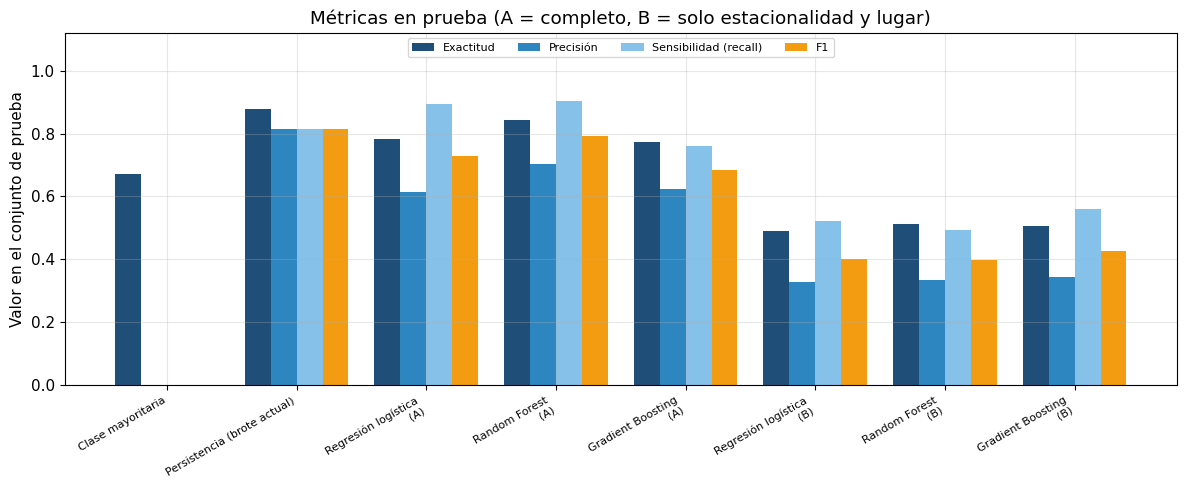

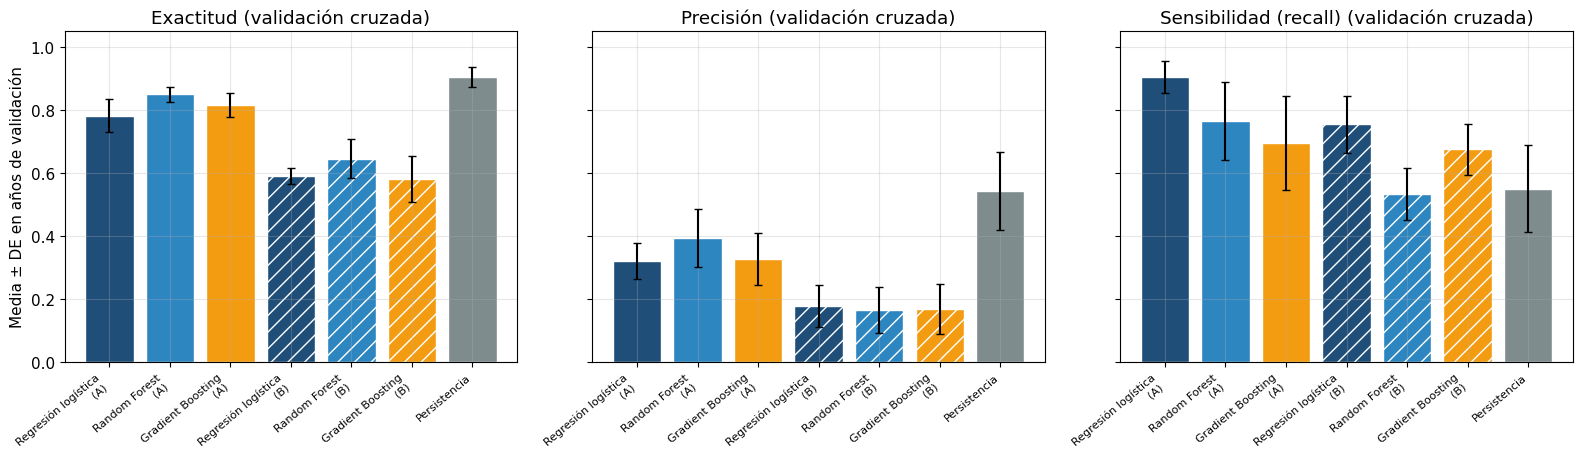

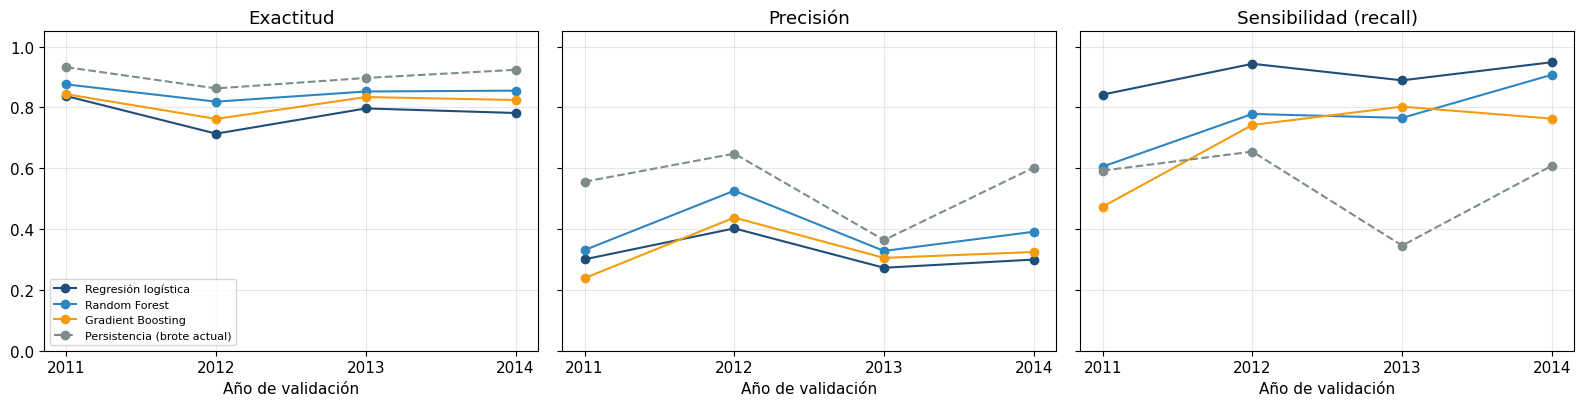

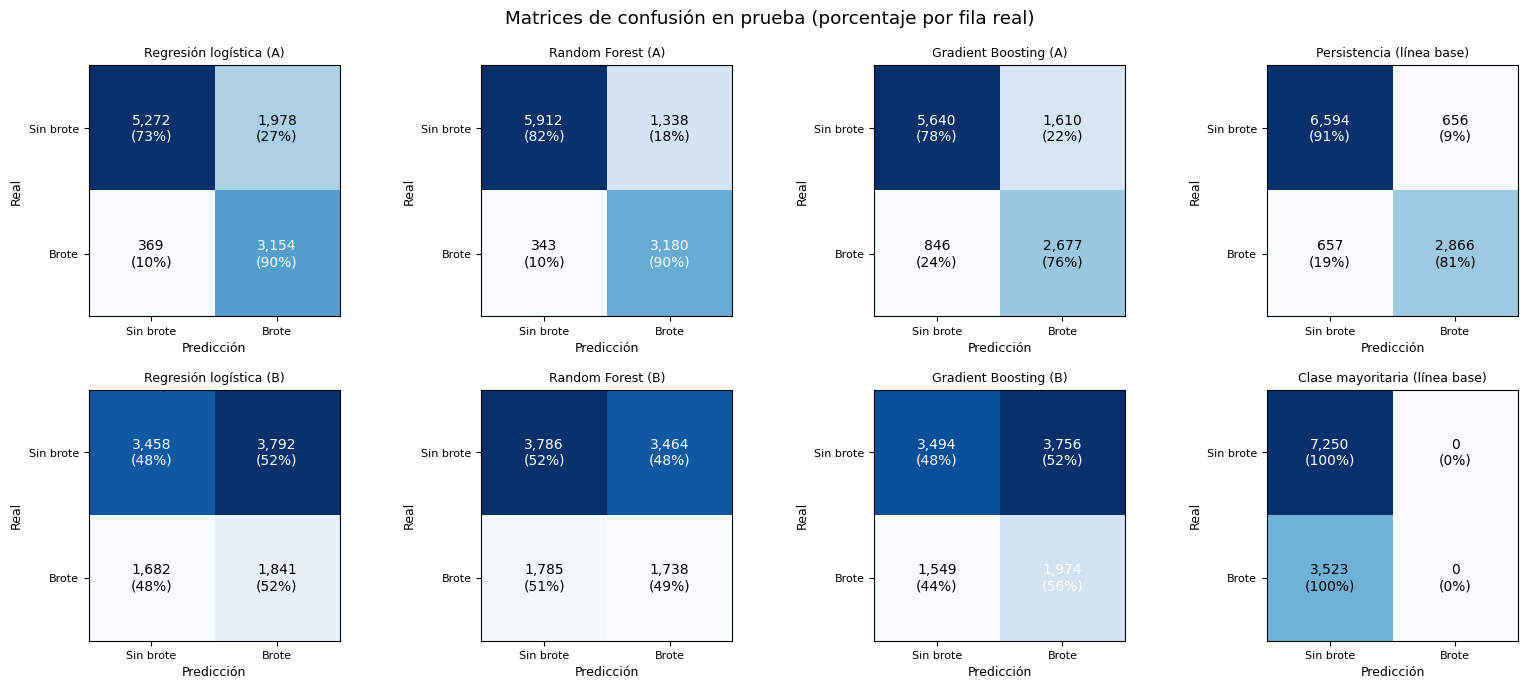

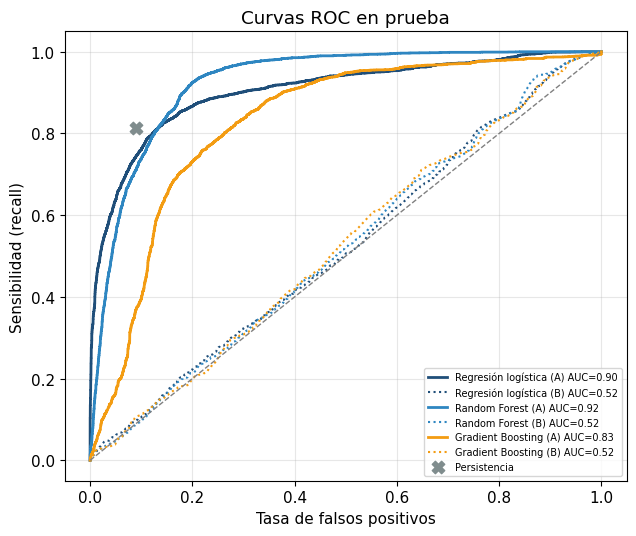

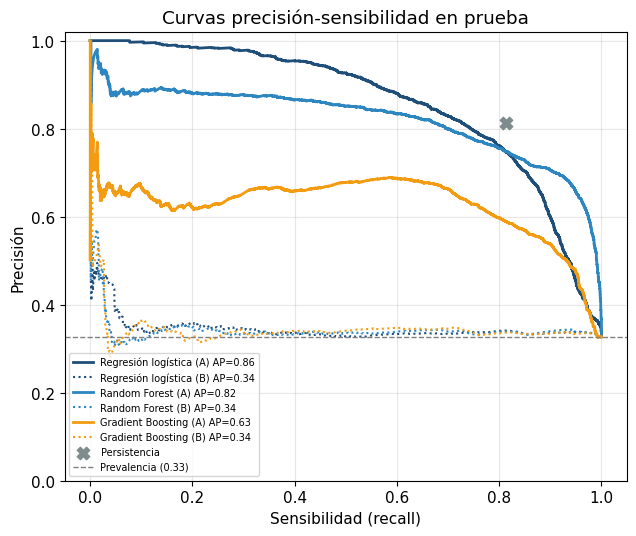

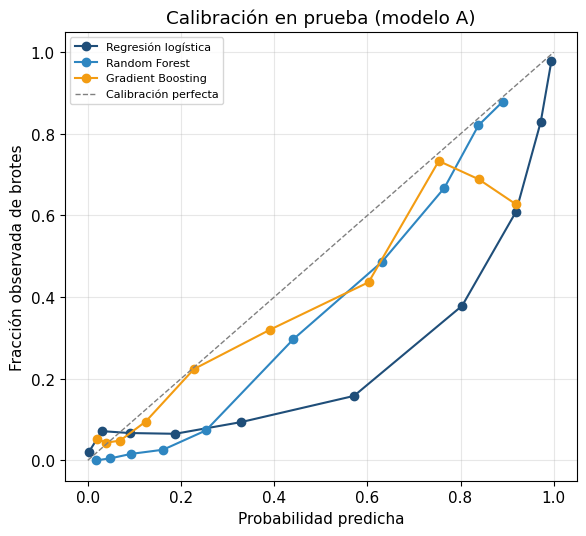

In [24]:
# Fig. 2: métricas en prueba, todos los modelos y líneas base
mostrar = res.copy()
mostrar["etiqueta"] = mostrar.apply(lambda r: r["modelo"] if r["conjunto"] == BASE
                                    else f"{r['modelo']}\n({r['conjunto'][0]})", axis=1)
fig, ax = plt.subplots(figsize=(12, 5))
xs = np.arange(len(mostrar))
bw = 0.2
for i, (m, c, lab) in enumerate(zip(METS, ["#1f4e79", "#2e86c1", "#85c1e9", "#f39c12"],
                                    ["Exactitud", "Precisión", "Sensibilidad (recall)", "F1"])):
    ax.bar(xs + (i - 1.5) * bw, mostrar[m], bw, label=lab, color=c)
ax.set_xticks(xs); ax.set_xticklabels(mostrar["etiqueta"], rotation=30, ha="right", fontsize=8)
ax.set_ylim(0, 1.12); ax.set_ylabel("Valor en el conjunto de prueba")
ax.set_title("Métricas en prueba (A = completo, B = solo estacionalidad y lugar)")
ax.legend(ncol=4, fontsize=8, loc="upper center")
guardar(fig, "figura2_metricas_prueba")

# Fig. 3: validación cruzada, media ± DE
orden = ([(CONJ_A, m) for m in MODELS] + [(CONJ_B, m) for m in MODELS] + [(BASE, PERS)])
cv_med = cv.groupby(["conjunto", "modelo"])[METS].mean()
cv_sd = cv.groupby(["conjunto", "modelo"])[METS].std()
etiq = [f"{m}\n({s[0]})" if s != BASE else "Persistencia" for s, m in orden]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, met, tit in zip(axes, ["exactitud", "precision", "sensibilidad"],
                        ["Exactitud", "Precisión", "Sensibilidad (recall)"]):
    for i, k in enumerate(orden):
        ax.bar(i, cv_med.loc[k, met], yerr=cv_sd.loc[k, met], capsize=3, color=COL[k[1]],
               hatch="//" if k[0] == CONJ_B else None, edgecolor="white")
    ax.set_xticks(range(len(orden))); ax.set_xticklabels(etiq, rotation=40, ha="right", fontsize=8)
    ax.set_title(f"{tit} (validación cruzada)"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Media ± DE en años de validación")
guardar(fig, "figura3_metricas_validacion_cruzada")

# Fig. 4: métricas por año de validación
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, met, tit in zip(axes, ["exactitud", "precision", "sensibilidad"],
                        ["Exactitud", "Precisión", "Sensibilidad (recall)"]):
    for m in list(MODELS) + [PERS]:
        sub = cv[(cv.modelo == m) & (cv.conjunto.isin([CONJ_A, BASE]))].sort_values("anio_validacion")
        ax.plot(sub["anio_validacion"], sub[met], marker="o", color=COL[m], label=m,
                ls="--" if m == PERS else "-")
    ax.set_xticks(VAL_YEARS); ax.set_title(tit); ax.set_xlabel("Año de validación"); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8)
guardar(fig, "figura4_validacion_por_anio")

# Fig. 5: matrices de confusión de todos los modelos
def dibujar_cm(ax, y, pred, titulo):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    tot_fila = cm.sum(axis=1, keepdims=True)
    for (i, j), v in np.ndenumerate(cm):
        pct = 100 * v / tot_fila[i, 0] if tot_fila[i, 0] else 0
        ax.text(j, i, f"{v:,}\n({pct:.0f}%)", ha="center", va="center", fontsize=10,
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Sin brote", "Brote"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Sin brote", "Brote"], fontsize=8)
    ax.set_xlabel("Predicción", fontsize=9); ax.set_ylabel("Real", fontsize=9)
    ax.set_title(titulo, fontsize=9)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, m in enumerate(MODELS):
    dibujar_cm(axes[0, j], te["y"], ajustados[(CONJ_A, m)][1], f"{m} (A)")
    dibujar_cm(axes[1, j], te["y"], ajustados[(CONJ_B, m)][1], f"{m} (B)")
dibujar_cm(axes[0, 3], te["y"], pred_pers, "Persistencia (línea base)")
dibujar_cm(axes[1, 3], te["y"], pred_maj, "Clase mayoritaria (línea base)")
fig.suptitle("Matrices de confusión en prueba (porcentaje por fila real)")
guardar(fig, "figura5_matrices_confusion")

# Fig. 6: curvas ROC
def punto_base(y, pred):
    cm = confusion_matrix(y, pred, labels=[0, 1]); vn, fp, fn, vp = cm.ravel()
    return fp / (fp + vn) if (fp + vn) else 0, vp / (vp + fn) if (vp + fn) else 0, vp / (vp + fp) if (vp + fp) else 0

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for m in MODELS:
    for s, ls in ((CONJ_A, "-"), (CONJ_B, ":")):
        fpr, tpr, _ = roc_curve(te["y"], ajustados[(s, m)][2])
        auc = roc_auc_score(te["y"], ajustados[(s, m)][2])
        ax.plot(fpr, tpr, ls=ls, color=COL[m], lw=2 if ls == "-" else 1.5, label=f"{m} ({s[0]}) AUC={auc:.2f}")
fpr_p, tpr_p, _ = punto_base(te["y"], pred_pers)
ax.scatter([fpr_p], [tpr_p], color=COL[PERS], marker="X", s=80, zorder=5, label="Persistencia")
ax.plot([0, 1], [0, 1], color="gray", lw=1, ls="--")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Sensibilidad (recall)")
ax.set_title("Curvas ROC en prueba"); ax.legend(fontsize=7, loc="lower right")
guardar(fig, "figura6_roc")

# Fig. 7: curvas precisión-sensibilidad
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for m in MODELS:
    for s, ls in ((CONJ_A, "-"), (CONJ_B, ":")):
        p, r, _ = precision_recall_curve(te["y"], ajustados[(s, m)][2])
        ap = average_precision_score(te["y"], ajustados[(s, m)][2])
        ax.plot(r, p, ls=ls, color=COL[m], lw=2 if ls == "-" else 1.5, label=f"{m} ({s[0]}) AP={ap:.2f}")
_, rec_p, pre_p = punto_base(te["y"], pred_pers)
ax.scatter([rec_p], [pre_p], color=COL[PERS], marker="X", s=80, zorder=5, label="Persistencia")
ax.axhline(te["y"].mean(), color="gray", ls="--", lw=1, label=f"Prevalencia ({te['y'].mean():.2f})")
ax.set_xlabel("Sensibilidad (recall)"); ax.set_ylabel("Precisión"); ax.set_ylim(0, 1.02)
ax.set_title("Curvas precisión-sensibilidad en prueba"); ax.legend(fontsize=7, loc="lower left")
guardar(fig, "figura7_precision_recall")

# Fig. 8: calibración
fig, ax = plt.subplots(figsize=(6, 5.5))
for m in MODELS:
    fr, mp = calibration_curve(te["y"], ajustados[(CONJ_A, m)][2], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", color=COL[m], label=m)
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Fracción observada de brotes")
ax.set_title("Calibración en prueba (modelo A)"); ax.legend(fontsize=8)
guardar(fig, "figura8_calibracion")

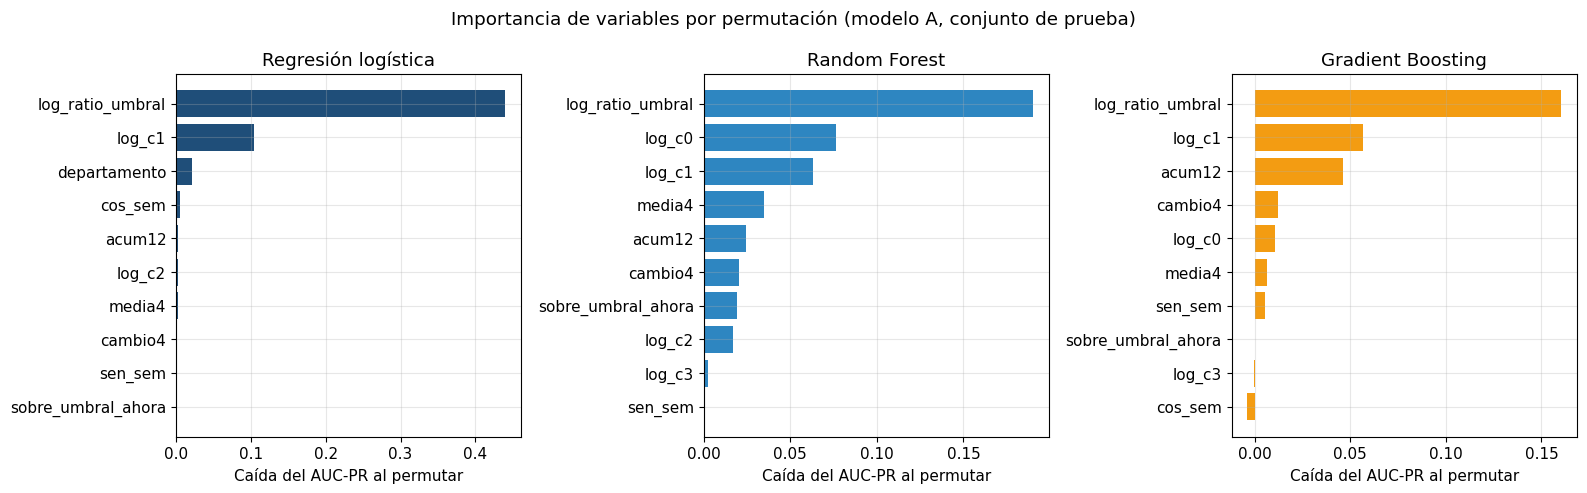

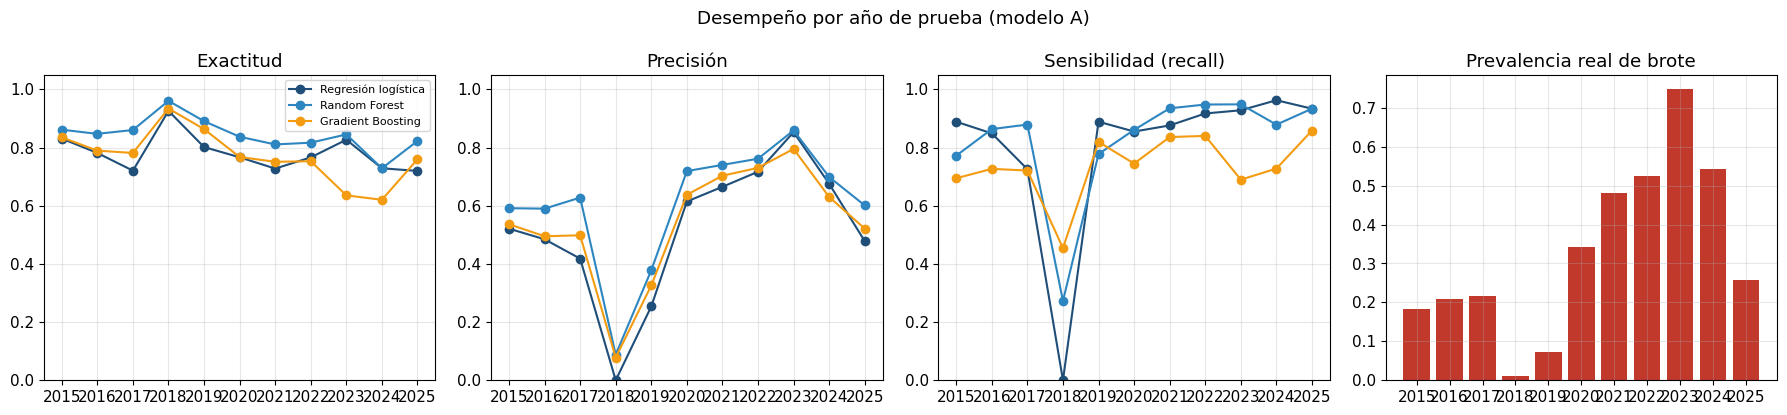

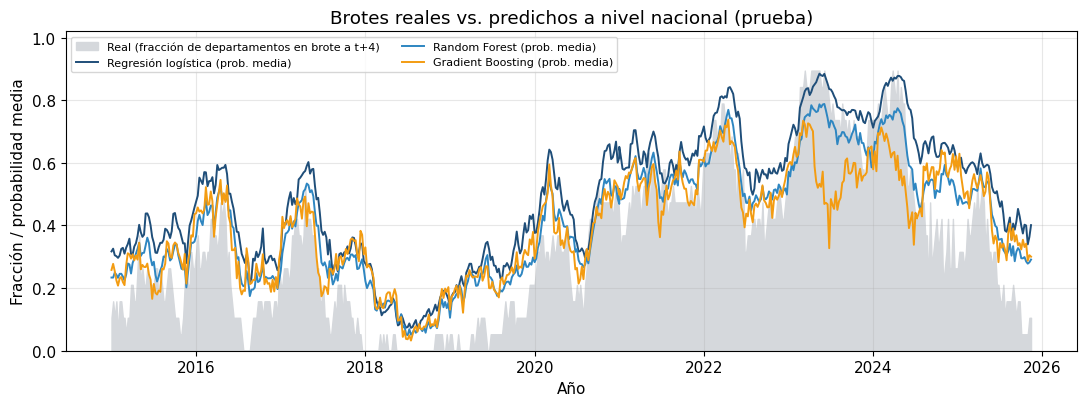

In [25]:
# Fig. 9: importancia por permutación agrupada (las dummies de departamento cuentan como una sola variable)
def importancia_grupos(mdl, X, y, grupos, n_rep=5, seed=SEED):
    rng = np.random.RandomState(seed)
    base = average_precision_score(y, mdl.predict_proba(X)[:, 1])
    out = {}
    for nombre, cols_g in grupos.items():
        caidas = []
        for _ in range(n_rep):
            Xp = X.copy()
            idx = rng.permutation(len(X))
            Xp[cols_g] = X[cols_g].to_numpy()[idx]
            caidas.append(base - average_precision_score(y, mdl.predict_proba(Xp)[:, 1]))
        out[nombre] = float(np.mean(caidas))
    return pd.Series(out).sort_values(ascending=False)

grupos = {c: [c] for c in NUM_A}
grupos["departamento"] = dep_cols
muestra = te.sample(min(3000, len(te)), random_state=SEED)
imps = {}
for m in MODELS:
    mdl_m, _, _, feats_m = ajustados[(CONJ_A, m)]
    imps[m] = importancia_grupos(mdl_m, muestra[feats_m], muestra["y"], grupos)
pd.DataFrame(imps).round(4).to_csv(f"{OUT}/importancia_variables.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, m in zip(axes, MODELS):
    top = imps[m].head(10)[::-1]
    ax.barh(top.index, top.values, color=COL[m])
    ax.set_title(m); ax.set_xlabel("Caída del AUC-PR al permutar")
fig.suptitle("Importancia de variables por permutación (modelo A, conjunto de prueba)")
guardar(fig, "figura9_importancia_variables")

# Fig. 10: desempeño por año de prueba, los tres modelos
filas_anio = []
for m in MODELS:
    _, pr, pb, _ = ajustados[(CONJ_A, m)]
    for a, g in te.assign(prob=pb, pred=pr).groupby("ano"):
        filas_anio.append({"modelo": m, "ano": a, "semanas_depto": len(g), "prevalencia": g["y"].mean(),
                           **metricas(g["y"], g["pred"], g["prob"])})
por_anio = pd.DataFrame(filas_anio)
por_anio.round(3).to_csv(f"{OUT}/desempeno_por_anio.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, met, tit in zip(axes[:3], ["exactitud", "precision", "sensibilidad"],
                        ["Exactitud", "Precisión", "Sensibilidad (recall)"]):
    for m in MODELS:
        sub = por_anio[por_anio.modelo == m]
        ax.plot(sub["ano"], sub[met], marker="o", color=COL[m], label=m)
    ax.set_title(tit); ax.set_ylim(0, 1.05); ax.set_xticks(sorted(te["ano"].unique()))
axes[0].legend(fontsize=8)
prev = por_anio[por_anio.modelo == best]
axes[3].bar(prev["ano"], prev["prevalencia"], color="#c0392b")
axes[3].set_title("Prevalencia real de brote"); axes[3].set_xticks(sorted(te["ano"].unique()))
fig.suptitle("Desempeño por año de prueba (modelo A)")
guardar(fig, "figura10_desempeno_por_anio")

# Fig. 11: fracción de departamentos en brote (real vs probabilidad media predicha)
tmp = te[["t", "ano", "semana", "y"]].copy()
for m in MODELS:
    tmp[m] = ajustados[(CONJ_A, m)][2]
agr = tmp.groupby("t").agg({"ano": "first", "semana": "first", "y": "mean", **{m: "mean" for m in MODELS}})
xx = agr["ano"] + (agr["semana"] - 1) / 52
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(xx, agr["y"], color="#d5d8dc", label="Real (fracción de departamentos en brote a t+%d)" % HORIZON)
for m in MODELS:
    ax.plot(xx, agr[m], color=COL[m], lw=1.4, label=f"{m} (prob. media)")
ax.set_xlabel("Año"); ax.set_ylabel("Fracción / probabilidad media"); ax.set_ylim(0, 1.02)
ax.set_title("Brotes reales vs. predichos a nivel nacional (prueba)")
ax.legend(fontsize=8, ncol=2)
guardar(fig, "figura11_real_vs_predicho")

## 8. Resumen final

In [26]:
orden_prueba = (res[res.conjunto == CONJ_A].set_index("modelo")[METS + ["AUC", "AUC_PR"]]
                .sort_values(CRITERIO_SELECCION, ascending=False).round(3))
print(f"Modelos (conjunto A) ordenados en PRUEBA por {CRITERIO_SELECCION}:")
display(orden_prueba)
print(f"\nModelo elegido en validación cruzada: {best}")
b = res[(res.conjunto == CONJ_A) & (res.modelo == best)].iloc[0]
p = res[res.modelo == PERS].iloc[0]
print(f"  Prueba -> exactitud={b['exactitud']:.3f} | precisión={b['precision']:.3f} | "
      f"sensibilidad={b['sensibilidad']:.3f} | F1={b['F1']:.3f}")
print(f"  Persistencia -> exactitud={p['exactitud']:.3f} | precisión={p['precision']:.3f} | "
      f"sensibilidad={p['sensibilidad']:.3f} | F1={p['F1']:.3f}")
print(f"\nTodas las tablas y figuras (300 dpi) están en ./{OUT}")

# Colab: descomentar para descargar todo en un zip
# !zip -r salidas_dengue.zip salidas_dengue
# from google.colab import files; files.download("salidas_dengue.zip")

Modelos (conjunto A) ordenados en PRUEBA por F1:


,exactitud,precision,sensibilidad,F1,AUC,AUC_PR
modelo,,,,,,
Random Forest,0.844,0.704,0.903,0.791,0.924,0.820
Regresión logística,0.782,0.615,0.895,0.729,0.904,0.859
Gradient Boosting,0.772,0.624,0.760,0.686,0.827,0.627



Modelo elegido en validación cruzada: Random Forest
  Prueba -> exactitud=0.844 | precisión=0.704 | sensibilidad=0.903 | F1=0.791
  Persistencia -> exactitud=0.878 | precisión=0.814 | sensibilidad=0.814 | F1=0.814

Todas las tablas y figuras (300 dpi) están en ./salidas_dengue
